# LES Intercomparison Study for CBL: Fourier Spectra

In [1]:
from IPython.display import display, Markdown
from datetime import datetime, timezone
display(Markdown(f"*Last run: {datetime.now(timezone.utc).strftime('%B %d, %Y at %H:%M UTC')}*"))

*Last run: November 24, 2026 at 13:52 UTC*

For case setup and physical parameters, see the [Description](CBL_N91_Description.ipynb) notebook.

One-sided Fourier power spectra of the streamwise velocity $u$ and potential temperature $\theta$ are computed at four height levels. The 1-D spectrum is computed along $x$ for each $y$ row and then averaged over $y$. Reference run: `384x384x384_LASDD_SM_SP` at $t = 3.5$ h.

## Setup

In [2]:
import re
import glob
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

### Output directory

In [3]:
def find_repo_root(start=None):
    path = Path(start or ('__file__' in globals() and __file__) or Path.cwd()).resolve()
    for candidate in (path, *path.parents):
        if (candidate / 'examples').is_dir() and (candidate / 'docs').is_dir():
            return candidate
    raise FileNotFoundError('Could not locate jaxalfa repository root')

BaseDir = find_repo_root()

# Results tree: 'examples' (DGX, A100), 'examples_A6000ada' (HAL, RTX 6000 Ada),
# 'examples_H100' (Empire AI, H100)
Platform = 'examples'

RunDir    = BaseDir / Platform / 'CBL_N91/runs/384x384x384_LASDD_SM_SP'
OutputDir = RunDir / 'output'

cfg = {}
exec((RunDir / 'Config.py').read_text(), cfg)

### Load 3D fields at $t = 3.5$ h

In [4]:
T_snapshot = 3.5 * 3600
dt = float(cfg['dt'])
iter_3D = int(T_snapshot / dt)
field_path = OutputDir / f'ALFA_3DFields_Iteration_{iter_3D}.npz'

nx = int(cfg['nx']); ny = int(cfg['ny']); nz = int(cfg['nz'])

if field_path.exists():
    File3D = np.load(field_path)
    u3D  = File3D['u']
    TH3D = File3D['TH']
    print(f'Loaded {field_path.name}  shape: {u3D.shape}')
else:
    print(f'Missing {field_path}; using NaN placeholders.')
    u3D  = np.full((nx, ny, nz), np.nan)
    TH3D = np.full((nx, ny, nz), np.nan)

Loaded ALFA_3DFields_Iteration_50400.npz  shape: (384, 384, 384)


### Grid parameters

In [5]:
l_x = float(cfg['l_x'])
l_z = float(cfg['l_z'])
dx  = l_x / nx

# Half levels — u and TH
z_u = np.array([(k + 0.5) * l_z / (nz - 1) for k in range(nz)])

# Height levels matching HorizontalCrossSections notebook
k_levels = [int(nz / 100), int(nz / 50), int(nz / 25), int(nz / 10)]
z_labels  = [f'{z_u[k]:.1f}' for k in k_levels]

print('Height levels (k, z):')
for k, zl in zip(k_levels, z_labels):
    print(f'  k={k:4d}  z={zl} m')
print(f'dx = {dx:.3f} m')

Height levels (k, z):
  k=   3  z=45.7 m
  k=   7  z=97.9 m
  k=  15  z=202.3 m
  k=  38  z=502.6 m
dx = 16.667 m


### Fourier spectrum

In [6]:
def FourSpectrum1D_LES(X, dx):
    """Compute 1-D one-sided power spectral density averaged over axis 1.

    Translated from LES_FourSpectrum.m (Sukanta Basu, 2005).

    Parameters
    ----------
    X : ndarray (NI, NJ)
        Field slice; axis 0 is the x-direction, axis 1 is averaged over (y).
    dx : float
        Grid spacing in the x-direction (m); sets the wavenumber bin width.

    Returns
    -------
    P : ndarray (NI//2 - 1,)  — PSD averaged over y; DC and Nyquist excluded.
        Units: [X]^2 / (rad m^-1)  (e.g. m^3 s^-2 rad^-1 for velocity).
    """
    NI, NJ = X.shape
    N = NI
    P = np.zeros(N)
    for j in range(NJ):
        f = np.fft.fft(X[:, j]) / N
        P += 2.0 * np.abs(f) ** 2
    P /= NJ
    dK = 2.0 * np.pi / (N * dx)   # wavenumber bin width (rad/m)
    return P[1 : N // 2] / dK     # convert to PSD per unit wavenumber

In [7]:
plt.rcParams.update({
    'text.usetex': True,
    'font.size': 14,
    'axes.labelsize': 16,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
})

## Fourier Spectra of $u$

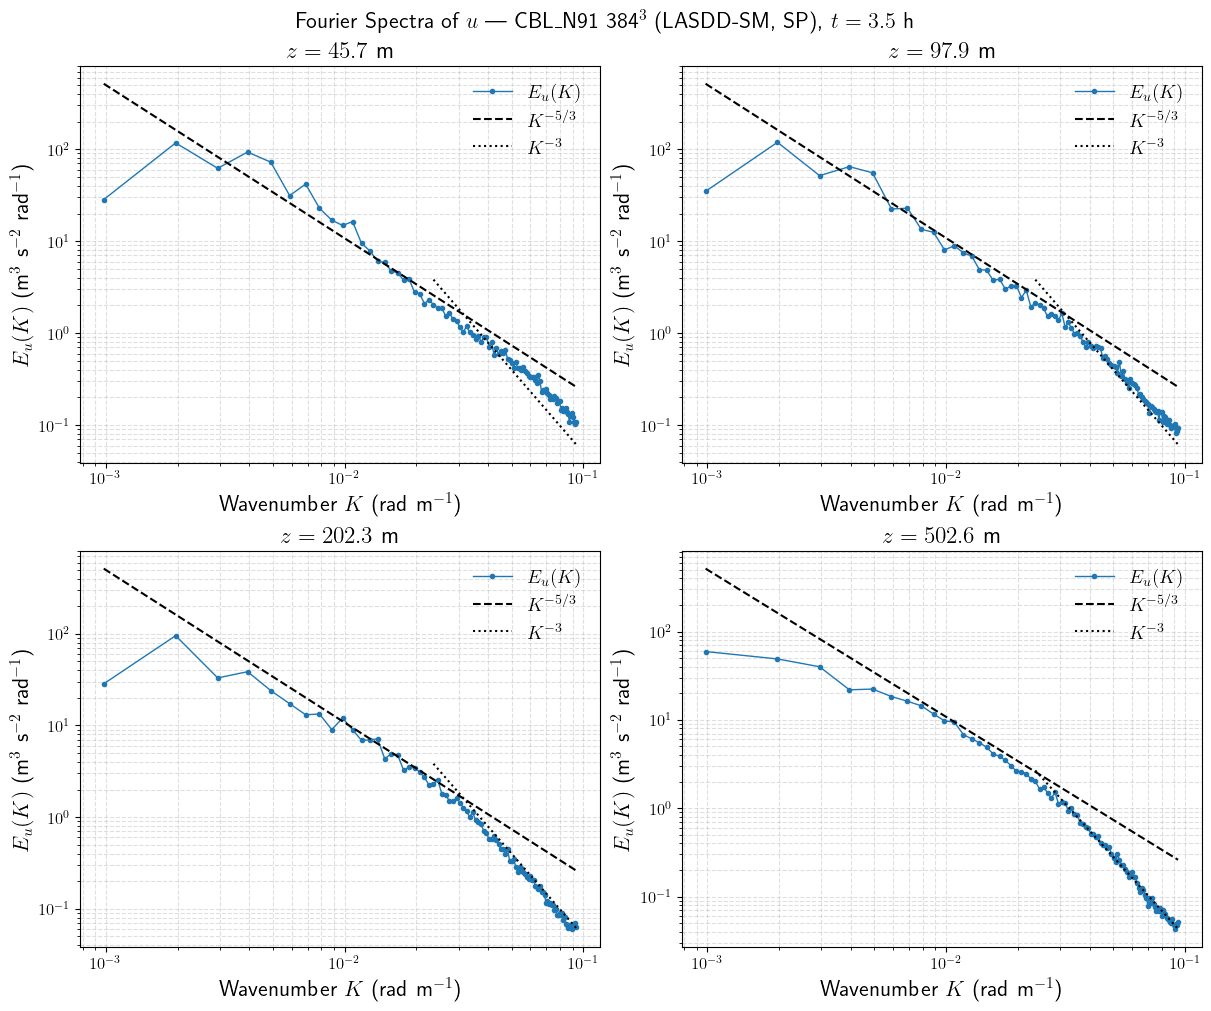

In [8]:
fig, axs = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)
axs = axs.flatten()

FGR  = float(cfg['FGR'])
N    = nx
K    = 2.0 * np.pi * np.arange(1, N // 2) / (N * dx)   # rad/m
K_c  = np.pi / (FGR * dx)                                # filter cutoff (rad/m)
mask_c = K < K_c
mask_hi = K[mask_c] >= 0.25 * K_c               # high-K region for K^{-3} reference

A_ref_u = [5e-3, 5e-3, 5e-3, 5e-3]   # one pre-factor per height level; adjust to shift K^{-5/3}
A_ref_u3 = [5e-5, 5e-5, 5e-5, 3.5e-5]   # adjust to shift K^{-3}

for i, k in enumerate(k_levels):
    P = FourSpectrum1D_LES(u3D[:, :, k], dx)

    ax = axs[i]
    ax.loglog(K[mask_c], P[mask_c], color='tab:blue', marker='o',
              markevery=1, markersize=3, linewidth=1.0, label=r'$E_u(K)$')
    ax.loglog(K[mask_c], A_ref_u[i] * K[mask_c] ** (-5 / 3), 'k--', linewidth=1.5, label=r'$K^{-5/3}$')
    ax.loglog(K[mask_c][mask_hi], A_ref_u3[i] * K[mask_c][mask_hi] ** (-3), 'k:', linewidth=1.5, label=r'$K^{-3}$')

    ax.set_title(rf'$z = {z_labels[i]}$ m')
    ax.set_xlabel(r'Wavenumber $K$ (rad m$^{-1}$)')
    ax.set_ylabel(r'$E_u(K)$ (m$^3$ s$^{-2}$ rad$^{-1}$)')
    ax.legend(frameon=False)
    ax.grid(True, which='both', ls='--', alpha=0.4)

fig.suptitle(r'Fourier Spectra of $u$ — CBL\_N91 384$^3$ (LASDD-SM, SP), $t=3.5$ h',
             fontsize=16)
plt.show()

## Fourier Spectra of $\theta$

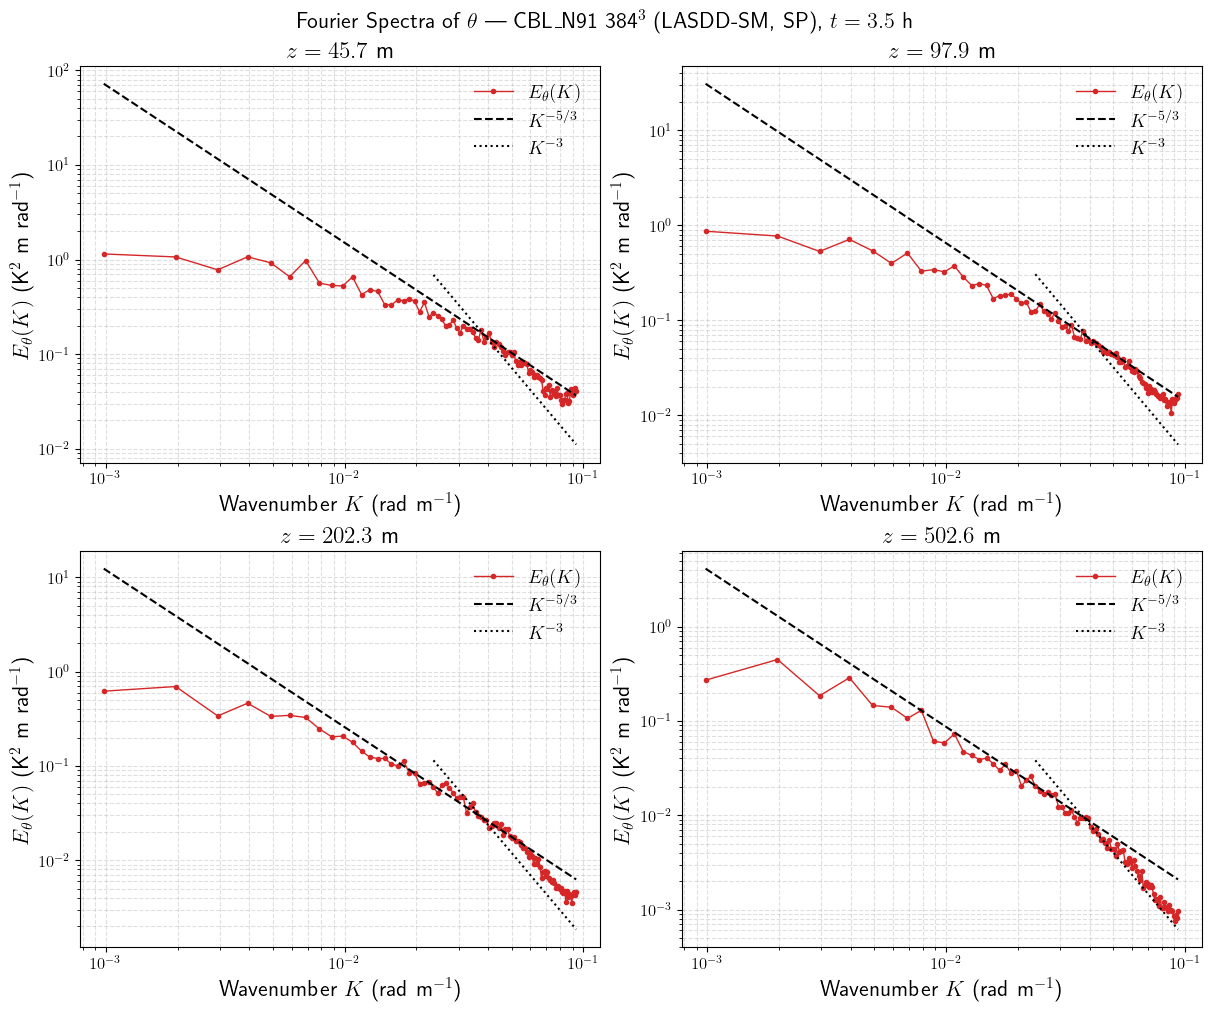

In [9]:
fig, axs = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)
axs = axs.flatten()

A_ref_th = [7e-4, 3e-4, 1.2e-4, 4e-5]   # one pre-factor per height level; adjust to shift K^{-5/3}
A_ref_th3 = [9e-6, 4e-6, 1.5e-6, 5e-7]   # adjust to shift K^{-3}

for i, k in enumerate(k_levels):
    P = FourSpectrum1D_LES(TH3D[:, :, k], dx)

    ax = axs[i]
    ax.loglog(K[mask_c], P[mask_c], color='tab:red', marker='o',
              markevery=1, markersize=3, linewidth=1.0, label=r'$E_\theta(K)$')
    ax.loglog(K[mask_c], A_ref_th[i] * K[mask_c] ** (-5 / 3), 'k--', linewidth=1.5, label=r'$K^{-5/3}$')
    ax.loglog(K[mask_c][mask_hi], A_ref_th3[i] * K[mask_c][mask_hi] ** (-3), 'k:', linewidth=1.5, label=r'$K^{-3}$')

    ax.set_title(rf'$z = {z_labels[i]}$ m')
    ax.set_xlabel(r'Wavenumber $K$ (rad m$^{-1}$)')
    ax.set_ylabel(r'$E_\theta(K)$ (K$^2$ m rad$^{-1}$)')
    ax.legend(frameon=False)
    ax.grid(True, which='both', ls='--', alpha=0.4)

fig.suptitle(r'Fourier Spectra of $\theta$ — CBL\_N91 384$^3$ (LASDD-SM, SP), $t=3.5$ h',
             fontsize=16)
plt.show()